In [1]:
import torch

torch.manual_seed(1337)

In [2]:
class MyLinear(torch.nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.weight = torch.nn.Parameter(torch.randn(out_features, in_features))
        self.bias = torch.nn.Parameter(torch.randn(out_features))

    def forward(self, x):
        return self.weight @ x + self.bias

In [3]:
class MyLayerNorm(torch.nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = torch.nn.Parameter(torch.ones(dim))
        self.beta = torch.nn.Parameter(torch.zeros(dim))

    def forward(self, x):
        x_normalized = (x - x.mean(dim=-1, keepdim=True)) / torch.sqrt(x.var(dim=-1, keepdim=True, unbiased=False))
        return self.gamma * x_normalized + self.beta

In [4]:
class FFN(torch.nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.layer_norm = MyLayerNorm(in_features)
        self.linear = MyLinear(in_features, out_features)
        self.relu = torch.nn.ReLU()
    
    def forward(self, x, config):
        if config.get("use_layer_norm", True):
            x = self.layer_norm(x)
        return self.relu(self.linear(x))

class MyNet(torch.nn.Module):
    def __init__(self, in_features, hidden_features, out_features):
        super().__init__()
        self.block = torch.nn.Sequential(
            FFN(in_features, hidden_features),
            FFN(hidden_features, hidden_features),
            FFN(hidden_features, hidden_features),
            FFN(hidden_features, hidden_features),
            FFN(hidden_features, hidden_features),
            FFN(hidden_features, hidden_features),
        )
        self.out = MyLinear(hidden_features, out_features)
    
    def forward(self, x, config):
        original_x = x.clone()
        if config.get("use_residuals", True):
            for layer in self.block:
                x = x + layer(x, config)
                print(f"Cosine similarity between original and current x: {torch.nn.functional.cosine_similarity(original_x.flatten(), x.flatten(), dim=0).item()}")
        else:
            for layer in self.block:
                x = layer(x, config)
                print(f"Cosine similarity between original and current x: {torch.nn.functional.cosine_similarity(original_x.flatten(), x.flatten(), dim=0).item()}")
        return self.out(x)

model = MyNet(in_features=10, hidden_features=10, out_features=1)

In [5]:
def stat_grads(model):
    for n, layer in enumerate(model.block):
        if isinstance(layer, FFN):
            print(f"Layer {n}:")
            print(f"  Linear weight grad mean: {torch.mean(layer.linear.weight.grad)}, std: {torch.std(layer.linear.weight.grad)}")
            print(f" Activation grad mean: {torch.mean(layer.linear.weight.grad)}, std: {torch.std(layer.linear.weight.grad)}")

In [6]:
x = torch.tensor([ 1,2,3,4,5,6,7,8,9,10], dtype=torch.float32)
config = {"use_residuals": False, "use_layer_norm": False}
y = model(x, config)
y.backward() # usage like this ensures starting with gradient of 1 for the output layer, and makes the comparison better
stat_grads(model)
model.zero_grad()

Cosine similarity between original and current x: 0.5607948303222656
Cosine similarity between original and current x: 0.29658669233322144
Cosine similarity between original and current x: 0.5815287232398987
Cosine similarity between original and current x: 0.4422699809074402
Cosine similarity between original and current x: 0.44275200366973877
Cosine similarity between original and current x: 0.22252224385738373
Layer 0:
  Linear weight grad mean: 22.551488876342773, std: 78.80272674560547
 Activation grad mean: 22.551488876342773, std: 78.80272674560547
Layer 1:
  Linear weight grad mean: 27.884292602539062, std: 63.433746337890625
 Activation grad mean: 27.884292602539062, std: 63.433746337890625
Layer 2:
  Linear weight grad mean: 6.922210693359375, std: 38.8173942565918
 Activation grad mean: 6.922210693359375, std: 38.8173942565918
Layer 3:
  Linear weight grad mean: 6.615855693817139, std: 37.044288635253906
 Activation grad mean: 6.615855693817139, std: 37.044288635253906
Layer

In [7]:
x = torch.tensor([ 1,2,3,4,5,6,7,8,9,10], dtype=torch.float32)
config = {"use_residuals": True, "use_layer_norm": False}
y = model(x, config)
y.backward()
stat_grads(model)
model.zero_grad()

Cosine similarity between original and current x: 0.7938441634178162
Cosine similarity between original and current x: 0.6428723335266113
Cosine similarity between original and current x: 0.7389442920684814
Cosine similarity between original and current x: 0.660393476486206
Cosine similarity between original and current x: 0.6189408302307129
Cosine similarity between original and current x: 0.440804123878479
Layer 0:
  Linear weight grad mean: 10.904075622558594, std: 116.05570983886719
 Activation grad mean: 10.904075622558594, std: 116.05570983886719
Layer 1:
  Linear weight grad mean: 23.533090591430664, std: 121.2040023803711
 Activation grad mean: 23.533090591430664, std: 121.2040023803711
Layer 2:
  Linear weight grad mean: 7.884682655334473, std: 127.1152114868164
 Activation grad mean: 7.884682655334473, std: 127.1152114868164
Layer 3:
  Linear weight grad mean: 17.482017517089844, std: 219.3482208251953
 Activation grad mean: 17.482017517089844, std: 219.3482208251953
Layer 4:

In [8]:
x = torch.tensor([ 1,2,3,4,5,6,7,8,9,10], dtype=torch.float32)
config = {"use_residuals": False, "use_layer_norm": True}
y = model(x, config)
y.backward()
stat_grads(model)
model.zero_grad()

Cosine similarity between original and current x: 0.3259296119213104
Cosine similarity between original and current x: 0.21764793992042542
Cosine similarity between original and current x: 0.6618174910545349
Cosine similarity between original and current x: 0.6088277101516724
Cosine similarity between original and current x: 0.578759491443634
Cosine similarity between original and current x: 0.3830510079860687
Layer 0:
  Linear weight grad mean: -5.9604643443123e-10, std: 0.3759307265281677
 Activation grad mean: -5.9604643443123e-10, std: 0.3759307265281677
Layer 1:
  Linear weight grad mean: -2.38418573772492e-09, std: 0.300754576921463
 Activation grad mean: -2.38418573772492e-09, std: 0.300754576921463
Layer 2:
  Linear weight grad mean: -2.38418573772492e-09, std: 0.7083631157875061
 Activation grad mean: -2.38418573772492e-09, std: 0.7083631157875061
Layer 3:
  Linear weight grad mean: -2.38418573772492e-09, std: 0.6374887824058533
 Activation grad mean: -2.38418573772492e-09, st

In [9]:
x = torch.tensor([ 1,2,3,4,5,6,7,8,9,10], dtype=torch.float32)
config = {"use_residuals": True, "use_layer_norm": True}
y = model(x, config)
y.backward()
stat_grads(model)
model.zero_grad()

Cosine similarity between original and current x: 0.9700738787651062
Cosine similarity between original and current x: 0.9455457329750061
Cosine similarity between original and current x: 0.894776463508606
Cosine similarity between original and current x: 0.895750880241394
Cosine similarity between original and current x: 0.9219151735305786
Cosine similarity between original and current x: 0.9192389249801636
Layer 0:
  Linear weight grad mean: -2.38418573772492e-09, std: 0.8199707865715027
 Activation grad mean: -2.38418573772492e-09, std: 0.8199707865715027
Layer 1:
  Linear weight grad mean: 4.5299529460862686e-08, std: 0.9021309614181519
 Activation grad mean: 4.5299529460862686e-08, std: 0.9021309614181519
Layer 2:
  Linear weight grad mean: -9.53674295089968e-09, std: 0.9294825196266174
 Activation grad mean: -9.53674295089968e-09, std: 0.9294825196266174
Layer 3:
  Linear weight grad mean: -1.907348590179936e-08, std: 0.9960523843765259
 Activation grad mean: -1.907348590179936e-

In [10]:
print(torch.std(x))

tensor(3.0277)


For this input and initialization, layer normalization greatly reduces weight-gradient magnitudes. Residual connections increase alignment between intermediate representations and the original input, especially when combined with layer normalization. Residuals alone increase gradient magnitudes, showing that a direct gradient path does not guarantee controlled scale

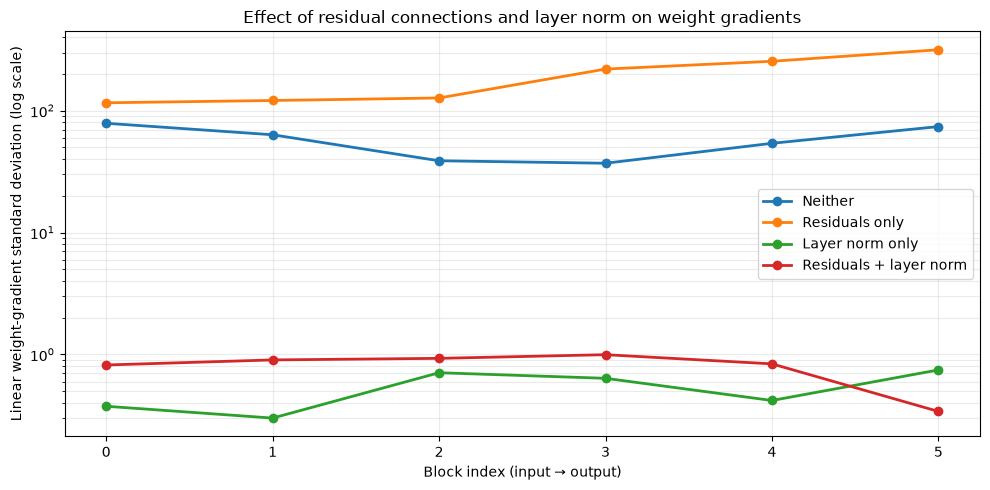

In [11]:
# If Matplotlib is missing in your notebook kernel, run: %pip install matplotlib
import contextlib
import io
import matplotlib.pyplot as plt

# Compare the same weights and input with a unit gradient at the output.
# autograd.grad returns gradients without accumulating into model parameters' .grad.
gradient_configs = [
    ("Neither", False, False),
    ("Residuals only", True, False),
    ("Layer norm only", False, True),
    ("Residuals + layer norm", True, True),
]
linear_weights = [layer.linear.weight for layer in model.block]
weight_gradient_stds = {}

for label, use_residuals, use_layer_norm in gradient_configs:
    plot_config = {
        "use_residuals": use_residuals,
        "use_layer_norm": use_layer_norm,
    }
    # Suppress the cosine-similarity printouts during plotting.
    with contextlib.redirect_stdout(io.StringIO()):
        plot_y = model(x, plot_config)
    weight_gradients = torch.autograd.grad(
        plot_y, linear_weights, grad_outputs=torch.ones_like(plot_y)
    )
    weight_gradient_stds[label] = [grad.std().item() for grad in weight_gradients]

block_indices = list(range(len(linear_weights)))
fig, ax = plt.subplots(figsize=(10, 5))
for label, stds in weight_gradient_stds.items():
    ax.plot(block_indices, stds, marker="o", linewidth=2, label=label)

# Log scale keeps the normalized and unnormalized configurations visible together.
ax.set_yscale("log")
ax.set_xticks(block_indices)
ax.set_xlabel("Block index (input → output)")
ax.set_ylabel("Linear weight-gradient standard deviation (log scale)")
ax.set_title("Effect of residual connections and layer norm on weight gradients")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


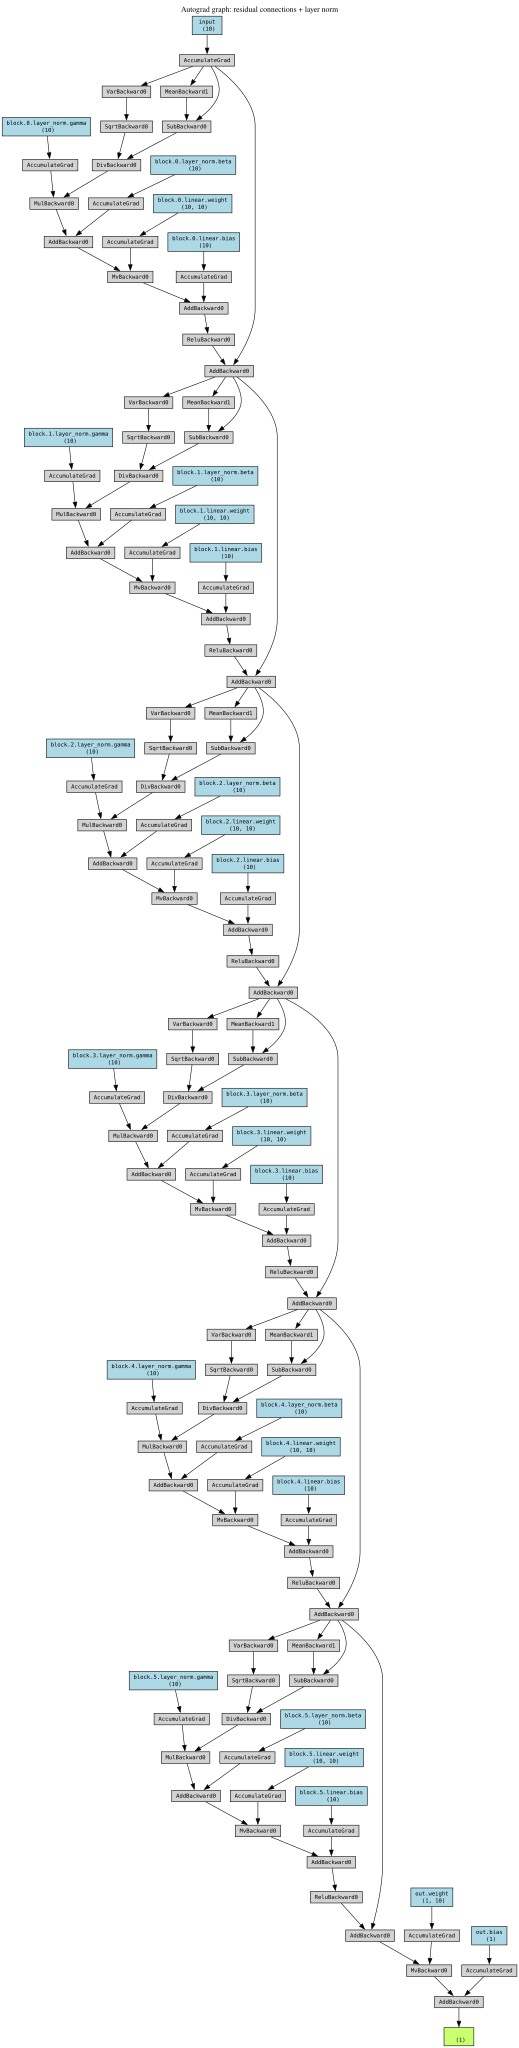

In [12]:
# Autograd computation graph: residual connections + layer normalization.
# Dependencies: %pip install torchviz
# Rendering also requires the Graphviz system executable `dot`
# (Ubuntu/Debian: sudo apt install graphviz).
import contextlib
import io
from IPython.display import display
from torchviz import make_dot

computation_graph_config = {"use_residuals": True, "use_layer_norm": True}
graph_input = x.detach().clone().requires_grad_(True)
with contextlib.redirect_stdout(io.StringIO()):
    graph_output = model(graph_input, computation_graph_config)

# Parameter names identify the six blocks; AddBackward nodes include the skip additions.
# This visualizes the operations used by autograd, rather than gradient magnitudes.
computation_graph = make_dot(
    graph_output,
    params={**dict(model.named_parameters()), "input": graph_input},
)
computation_graph.format = "svg"
computation_graph.graph_attr.update(
    rankdir="TB",
    label="Autograd graph: residual connections + layer norm",
    labelloc="t",
)
display(computation_graph)


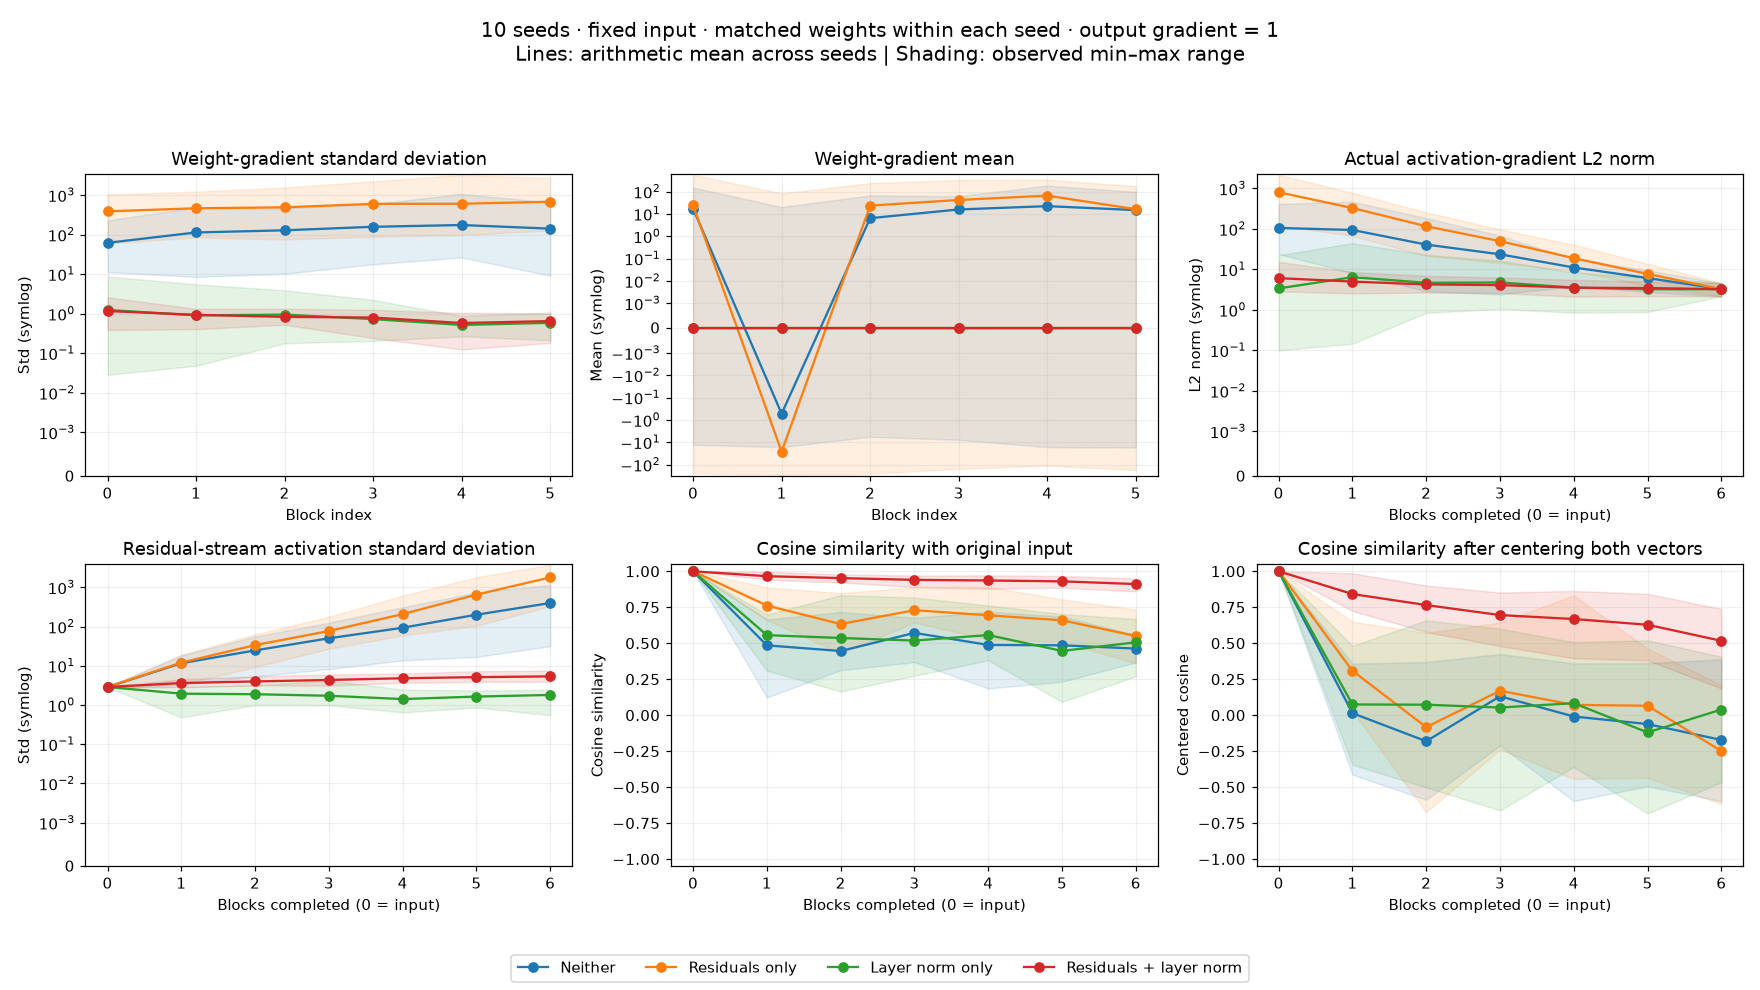

In [ ]:
# Run all four configurations over 10 initializations; display only the figure.
import contextlib
import io
import torch
import matplotlib.pyplot as plt

experiment_seeds = list(range(10))
experiment_input = torch.arange(1, 11, dtype=torch.float32)
experiment_configs = [
    ("Neither", False, False),
    ("Residuals only", True, False),
    ("Layer norm only", False, True),
    ("Residuals + layer norm", True, True),
]
metric_names = [
    "weight_grad_std", "weight_grad_mean", "activation_grad_norm",
    "activation_std", "cosine", "centered_cosine",
]
seed_results = {
    label: {metric: [] for metric in metric_names}
    for label, _, _ in experiment_configs
}

# Capture actual residual-stream activations from the existing forward method.
def capture_stream(module, inputs):
    activation = inputs[0]
    activation.retain_grad()
    stream_activations.append(activation)

# Preserve the notebook's CPU random-generator state and original model.
with torch.random.fork_rng(devices=[]):
    for seed in experiment_seeds:
        torch.manual_seed(seed)
        seed_model = MyNet(in_features=10, hidden_features=10, out_features=1)
        # Reuse identical weights for all four configurations within this seed.
        for label, use_residuals, use_layer_norm in experiment_configs:
            seed_model.zero_grad(set_to_none=True)
            seed_input = experiment_input.clone().requires_grad_(True)
            stream_activations = []
            handles = [
                layer.register_forward_pre_hook(capture_stream)
                for layer in seed_model.block
            ]
            handles.append(seed_model.out.register_forward_pre_hook(capture_stream))
            try:
                with contextlib.redirect_stdout(io.StringIO()):
                    seed_output = seed_model(seed_input, {
                        "use_residuals": use_residuals,
                        "use_layer_norm": use_layer_norm,
                    })
                seed_output.backward()  # Same output gradient of 1 in every test.
            finally:
                for handle in handles:
                    handle.remove()

            results = seed_results[label]
            weights = [layer.linear.weight for layer in seed_model.block]
            results["weight_grad_std"].append([w.grad.std().item() for w in weights])
            results["weight_grad_mean"].append([w.grad.mean().item() for w in weights])
            results["activation_grad_norm"].append([
                h.grad.norm().item() for h in stream_activations
            ])
            results["activation_std"].append([
                h.detach().std(unbiased=False).item() for h in stream_activations
            ])
            results["cosine"].append([
                torch.nn.functional.cosine_similarity(
                    seed_input.detach(), h.detach(), dim=0
                ).item() for h in stream_activations
            ])
            centered_input = seed_input.detach() - seed_input.detach().mean()
            results["centered_cosine"].append([
                torch.nn.functional.cosine_similarity(
                    centered_input, h.detach() - h.detach().mean(), dim=0
                ).item() for h in stream_activations
            ])

# Each metric has shape [10 seeds, number of blocks or stream positions].
seed_results = {
    label: {metric: torch.tensor(values) for metric, values in metrics.items()}
    for label, metrics in seed_results.items()
}
if not all(torch.isfinite(values).all() for metrics in seed_results.values()
           for values in metrics.values()):
    raise ValueError("Nonfinite results: check that MyLayerNorm adds eps to its variance.")

panels = [
    ("weight_grad_std", "Weight-gradient standard deviation", "Std", True),
    ("weight_grad_mean", "Weight-gradient mean", "Mean", True),
    ("activation_grad_norm", "Actual activation-gradient L2 norm", "L2 norm", True),
    ("activation_std", "Residual-stream activation standard deviation", "Std", True),
    ("cosine", "Cosine similarity with original input", "Cosine similarity", False),
    ("centered_cosine", "Cosine similarity after centering both vectors", "Centered cosine", False),
]
fig_seeds, axes_seeds = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, title, ylabel, use_symlog) in zip(axes_seeds.flat, panels):
    for label, _, _ in experiment_configs:
        values = seed_results[label][metric]
        positions = list(range(values.shape[1]))
        line, = ax.plot(positions, values.mean(dim=0).numpy(), marker="o", label=label)
        # Shading is the observed min–max range, not a confidence interval.
        ax.fill_between(positions, values.amin(dim=0).numpy(), values.amax(dim=0).numpy(),
                        color=line.get_color(), alpha=0.12)
    ax.set_title(title)
    ax.set_xlabel("Block index" if metric.startswith("weight")
                  else "Blocks completed (0 = input)")
    ax.set_xticks(positions)
    ax.set_ylabel(ylabel + (" (symlog)" if use_symlog else ""))
    if use_symlog:
        # Supports zero and negative means while showing large scale differences.
        ax.set_yscale("symlog", linthresh=1e-3)
        if metric != "weight_grad_mean":
            ax.set_ylim(bottom=0)
    if "cosine" in metric:
        ax.set_ylim(-1.05, 1.05)
    ax.grid(True, which="both", alpha=0.2)

legend_handles, legend_labels = axes_seeds[0, 0].get_legend_handles_labels()
fig_seeds.legend(legend_handles, legend_labels, loc="lower center", ncol=4)
fig_seeds.suptitle(
    "10 seeds · fixed input · matched weights within each seed · output gradient = 1\n"
    "Lines: arithmetic mean across seeds | Shading: observed min–max range", fontsize=13,
)
fig_seeds.tight_layout(rect=(0, 0.06, 1, 0.93))
plt.show()
